
# Consistency Models

A small-scale reproduction of *Consistency Models* (Song et al., 2023) on MNIST,
written as a tutorial. Consistency models generate an image with **one** network
evaluation, instead of the tens of evaluations a diffusion model needs. This
notebook walks through every piece of the project with the trained models:

1. **Setup**: data and device.
2. **The teachers**: a Variance Exploding (VE) diffusion model and a Rectified
   Flow (RF) model, and how they generate images step by step.
3. **Consistency models**: the parameterization, consistency distillation (CD)
   from each teacher, one-step and multistep sampling, and consistency training
   (CT and improved CT) without a teacher.
4. **Evaluation**: the classifier-based metrics (FD-MNIST, recognizable
   fraction, label entropy) and the sampling time.
5. **Summary**.

All models are loaded from `checkpoints/`, so nothing is trained here; the whole
notebook runs in about two minutes on a CPU. It uses the code in `system/` and
must be run from the `notebook/` folder or from the root of the repository. The
full results and their discussion are in the report (`memoria/memoria.pdf`) and
in `results/`.


## 1. Setup

Imports, device, random seed and a first look at MNIST, whose pixels are scaled
to $[-1, 1]$.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "system").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "system"))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import torch

from data import get_dataloader
from utils import get_device, set_seed

SEED = 42
set_seed(SEED)
device = get_device()
print("Device:", device)

[INFO] Seed set to 42
Device: cpu


Batch: (16, 1, 28, 28) | pixel range: (-1.0, 1.0)


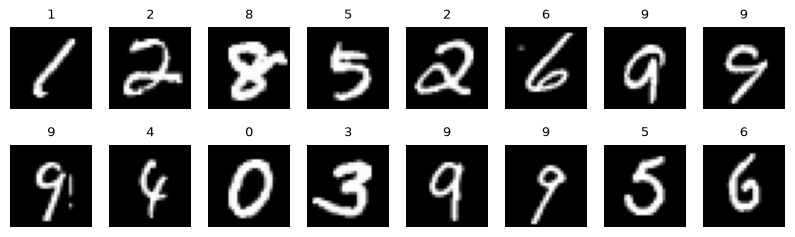

In [2]:
images, labels = next(iter(get_dataloader(batch_size=16, train=True, data_dir="./data")))
print("Batch:", tuple(images.shape), "| pixel range:", (images.min().item(), images.max().item()))

fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for ax, image, label in zip(axes.flat, images, labels):
    ax.imshow((image[0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.set_title(int(label), fontsize=9)
    ax.axis("off")
plt.show()

## 2. The teachers

A consistency model is distilled from a *teacher*: a model that already knows
how to turn noise into digits, but needs many network evaluations (NFE) to do
it. We use two teachers, both trained with the scripts of the project:

1. a **Variance Exploding (VE) diffusion** model, the teacher of the original
   paper;
2. a **Rectified Flow (RF)** model, a flow-matching alternative.

Each teacher defines a *forward process* that turns an image $x_0$ into noise,
and a deterministic *ODE* that undoes it. Solving that ODE step by step is
what makes the teachers slow, and it is exactly what the consistency model
will learn to do in a single step.

In this section we load both teachers, look at their forward processes and
sample from them with different numbers of steps. First, the imports and a
small helper to plot rows of images.

In [3]:
from consistency.teachers import VETeacherAdapter
from diffusion.ve import VarianceExplodingDiffusion
from evaluation.compare import EPS, SIGMA, SIGMA_NOISE, load_state
from flow_matching.rectified_flow import RectifiedFlow
from models.score_unet import ScoreNet
from models.velocity_unet import VelocityNet
from sampling.rectified_flow_sampler import RectifiedFlowSampler

# evaluation.compare switches matplotlib to a non-interactive backend.
%matplotlib inline

N_SHOW = 8


def show_rows(rows, title):
    # One row of N_SHOW images per entry of `rows` (label -> images in [-1, 1]).
    fig, axes = plt.subplots(len(rows), N_SHOW, figsize=(10, 1.4 * len(rows)), squeeze=False)
    for row, (label, batch) in zip(axes, rows.items()):
        for ax, image in zip(row, batch[:N_SHOW]):
            ax.imshow((image[0].clamp(-1, 1).cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
            ax.axis("off")
        row[0].set_title(label, fontsize=9, loc="left")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### 2.1 Variance Exploding diffusion

#### The forward process

The VE process only adds Gaussian noise to the image:

$$x_t = x_0 + \sigma(t)\, z, \qquad z \sim \mathcal{N}(0, I), \qquad
\sigma(t) = \sqrt{\frac{\sigma^{2t} - 1}{2 \ln \sigma}}, \qquad \sigma = 25.$$

It is implemented in `system/diffusion/ve.py`. Let us apply it to one digit
of the batch above at increasing times $t \in [0, 1]$.

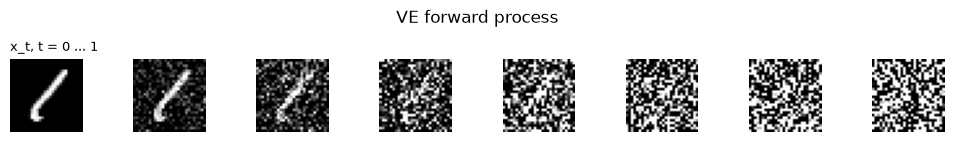

sigma(t): [0.0, 0.48, 0.91, 1.52, 2.45, 3.91, 6.21, 9.85]


In [4]:
ve = VarianceExplodingDiffusion(sigma=SIGMA)

x_0 = images[:1].to(device).expand(N_SHOW, -1, -1, -1)  # the same digit N_SHOW times
t = torch.linspace(0.0, 1.0, N_SHOW, device=device)
x_t = x_0 + ve.sigma_t(t).view(-1, 1, 1, 1) * torch.randn_like(x_0)

show_rows({"x_t, t = 0 ... 1": x_t}, "VE forward process")
print("sigma(t):", [round(s, 2) for s in ve.sigma_t(t).tolist()])

The noise grows exponentially: at $t = 1$ its standard deviation is about 10,
far larger than the pixel range $[-1, 1]$, so nothing of the digit is left.

#### The score network

`system/training/ve_training.py` trains a U-Net, `ScoreNet`
(`system/models/score_unet.py`), with denoising score matching: given $x_t$
and $t$, it predicts the score $\nabla_x \log p_t(x_t)$, the direction that
removes noise. We load the EMA weights saved by the training script.

In [5]:
score_net = load_state(ScoreNet(marginal_prob_std=ve.sigma_t), "./checkpoints/mnist_all_ve_ema.pth", device)
print(f"ScoreNet parameters: {sum(p.numel() for p in score_net.parameters()):,}")

ScoreNet parameters: 1,115,425


#### Sampling: the probability flow ODE

To generate, we start from pure noise $x_1 \sim \mathcal{N}(0, \sigma(1)^2 I)$
and integrate the *probability flow ODE* backwards, from $t = 1$ to
$t = \varepsilon$:

$$\frac{dx}{dt} = -\tfrac{1}{2}\, g(t)^2\, \nabla_x \log p_t(x).$$

`VETeacherAdapter` (`system/consistency/teachers.py`) takes one **Heun step**
of this ODE, on a Karras time grid. It is the same step the teacher takes
during consistency distillation and in the evaluation. A Heun step costs two
network evaluations, so $n$ steps cost $\text{NFE} = 2n$.

In [6]:
ve_teacher = VETeacherAdapter(process=ve, model=score_net, eps=EPS, heun=True)


def ve_generate(x, n_steps):
    # n Heun steps of the probability flow ODE, from t = 1 down to eps.
    times = ve_teacher.time_grid(n_steps + 1).flip(0).to(device)
    with torch.no_grad():
        for t, t_prev in zip(times[:-1], times[1:]):
            x = ve_teacher.ode_step(x, t.expand(x.shape[0]), t_prev.expand(x.shape[0]))
    return x

We sample with 5, 10 and 50 steps, all from the **same initial noise**, so
each column shows how the same starting point evolves with more steps.

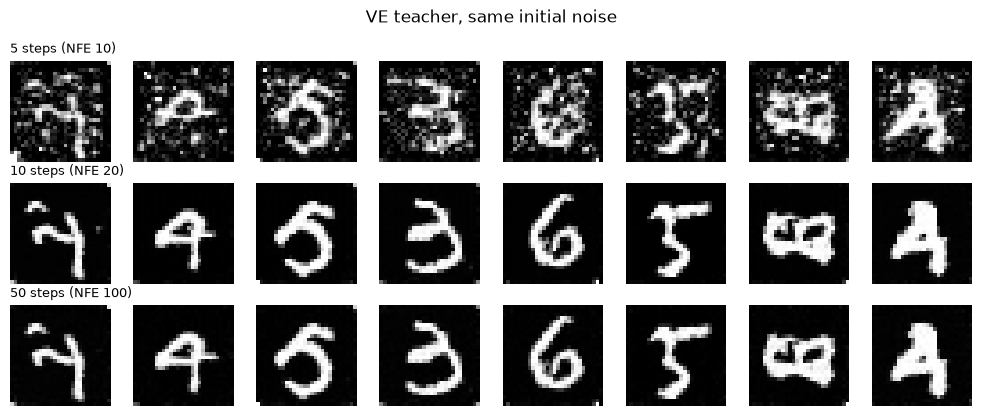

In [7]:
ve_std = ve.sigma_t(torch.ones(1)).item()
x_T_ve = torch.randn(N_SHOW, 1, 28, 28, generator=torch.Generator().manual_seed(SEED)).to(device) * ve_std

show_rows({f"{n} steps (NFE {2 * n})": ve_generate(x_T_ve, n) for n in [5, 10, 50]},
          "VE teacher, same initial noise")

With 5 steps the digits are still noisy; with 10 they are already clean, and
50 steps barely change them. Good samples need around 20 network evaluations.
This is the cost that consistency models aim to remove.

### 2.2 Rectified Flow

#### The forward process

Rectified Flow joins each image and a noise sample with a **straight line**:

$$x_t = (1 - t)\, x_0 + t\, x_1, \qquad x_1 \sim \mathcal{N}(0, I).$$

At $t = 0$ we have the image and at $t = 1$ pure noise
(`system/flow_matching/rectified_flow.py`). Unlike VE, the image fades out
while the noise fades in.

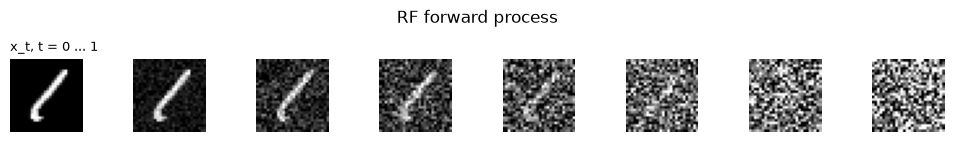

In [8]:
rf = RectifiedFlow(sigma_noise=SIGMA_NOISE, eps=EPS)

x_t = rf.interpolate(x_0, rf.sample_prior(x_0.shape, device=device), t)
show_rows({"x_t, t = 0 ... 1": x_t}, "RF forward process")

#### The velocity network

Along the straight path, the velocity $dx_t/dt = x_1 - x_0$ is constant.
`system/training/rectified_flow_training.py` trains a `VelocityNet`
(`system/models/velocity_unet.py`, the same U-Net as the score network) to
regress it from $(x_t, t)$:

$$\mathcal{L} = \mathbb{E}\, \big\| v_\theta(x_t, t) - (x_1 - x_0) \big\|^2.$$

We also load the **reflowed teacher (2-RF)**. `system/training/reflow_training.py`
generates (noise, image) pairs with the first teacher (1-RF) and retrains it
on them. Each image is then always paired with the same noise, so the paths
cross less and become straighter.

As for VE, we load the EMA weights of each teacher (an exponential moving
average of the weights during training), which give a better teacher than
the raw weights (see the report).

In [9]:
rf_teachers = {
    "1-RF": load_state(VelocityNet(), "./checkpoints/mnist_all_rf_ema.pth", device),
    "2-RF (reflow)": load_state(VelocityNet(), "./checkpoints/mnist_all_2rf_ema.pth", device),
}
print(f"VelocityNet parameters: {sum(p.numel() for p in rf_teachers['1-RF'].parameters()):,}")

VelocityNet parameters: 1,115,425


#### Sampling: Euler steps of the RF ODE

Samples are generated by integrating $dx/dt = v_\theta(x, t)$ from $t = 1$ to
$t = 0$ with Euler steps, $x \leftarrow x + (t_{i+1} - t_i)\, v_\theta(x, t_i)$
(`system/sampling/rectified_flow_sampler.py`), one network evaluation per
step. If the learned paths were perfectly straight, **a single step** would
reach the image. We sample both teachers with 1, 10 and 50 steps from the
same noise.

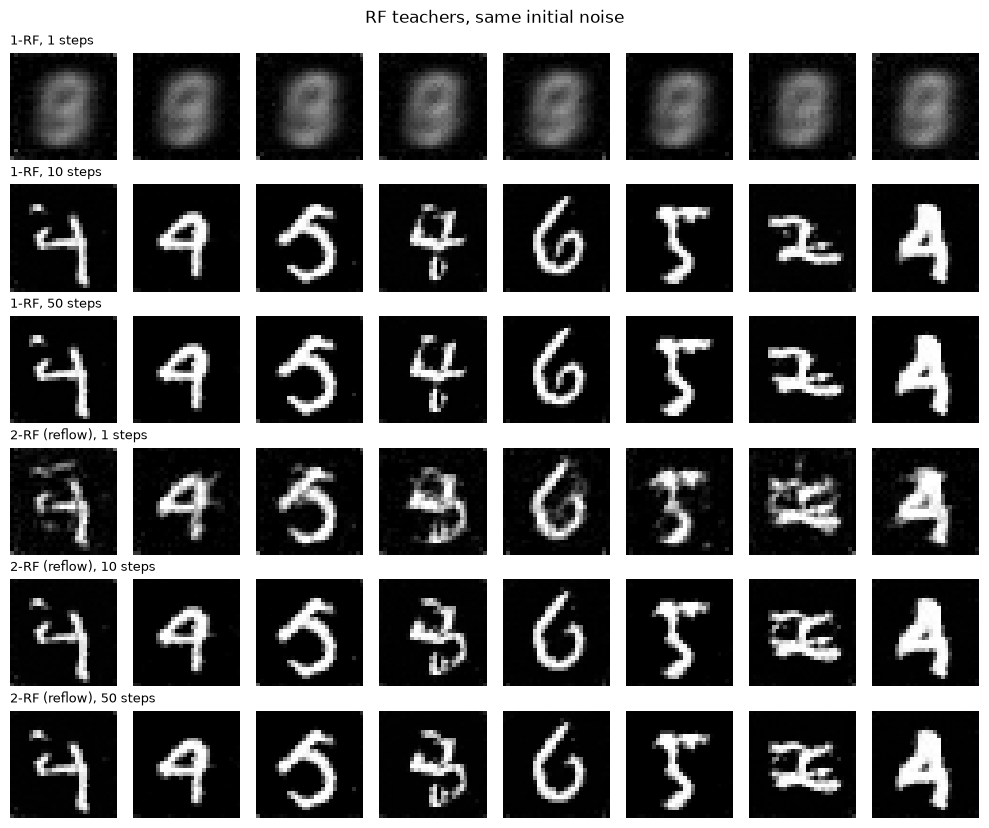

In [10]:
x_T_rf = torch.randn(N_SHOW, 1, 28, 28, generator=torch.Generator().manual_seed(SEED)).to(device) * SIGMA_NOISE

rows = {}
for name, velocity_net in rf_teachers.items():
    for n in [1, 10, 50]:
        sampler = RectifiedFlowSampler(rf, n_steps=n)
        _, x = sampler.sample(tuple(x_T_rf.shape), velocity_net, device=device, x_T=x_T_rf)
        rows[f"{name}, {n} steps"] = x * 2 - 1  # the sampler returns images in [0, 1]
show_rows(rows, "RF teachers, same initial noise")

With one step the 1-RF only produces a blurry *average digit*: its paths are
curved, so following the initial direction for the whole way misses the
image. The 2-RF already gives recognizable digits in one step, because reflow
made its paths straighter. With 10 or more steps both teachers produce clean
digits.

Both teachers are still slow, though. In the next section we distill them
into consistency models that generate in one to four steps.

## 3. Consistency models

### 3.1 Consistency distillation

#### The consistency function

Each teacher's ODE maps a noisy image $x_t$ to a clean image along a
trajectory. A **consistency model** $f_\theta(x_t, t)$ learns to jump from
*any* point of a trajectory directly to its end:

$$f_\theta(x_t, t) = x_\varepsilon \quad \text{for every } t \in [\varepsilon, T],$$

so that every point of the same trajectory gives the same output
(*self-consistency*). At $t = \varepsilon$ the image is already clean, so the
model must satisfy the **boundary condition** $f_\theta(x, \varepsilon) = x$.

`ConsistencyWrapper` (`system/models/consistency_wrapper.py`) enforces it by
construction. It wraps a U-Net $F_\theta$, the same architecture as the
teachers:

$$f_\theta(x, t) = c_\text{skip}(t)\, x + c_\text{out}(t)\, F_\theta\big(c_\text{in}(t)\, x,\ t\big),$$

with the coefficients of Karras et al. (EDM), computed from each teacher's
noise scale $\sigma(t)$ and $\sigma_\text{data} = 0.5$:

$$c_\text{skip}(t) = \frac{\sigma_\text{data}^2}{(\sigma(t) - \sigma(\varepsilon))^2 + \sigma_\text{data}^2}, \qquad
c_\text{out}(t) = \frac{\sigma_\text{data}\,(\sigma(t) - \sigma(\varepsilon))}{\sqrt{\sigma(t)^2 + \sigma_\text{data}^2}}, \qquad
c_\text{in}(t) = \frac{1}{\sqrt{\sigma(t)^2 + \sigma_\text{data}^2}}.$$

At $t = \varepsilon$, $c_\text{skip} = 1$ and $c_\text{out} = 0$, so the
output is exactly $x$ whatever the network does. Let us check it on the
trained CM-VE and plot the coefficients for both teachers.

Boundary condition: max |f(x, eps) - x| = 0.0e+00


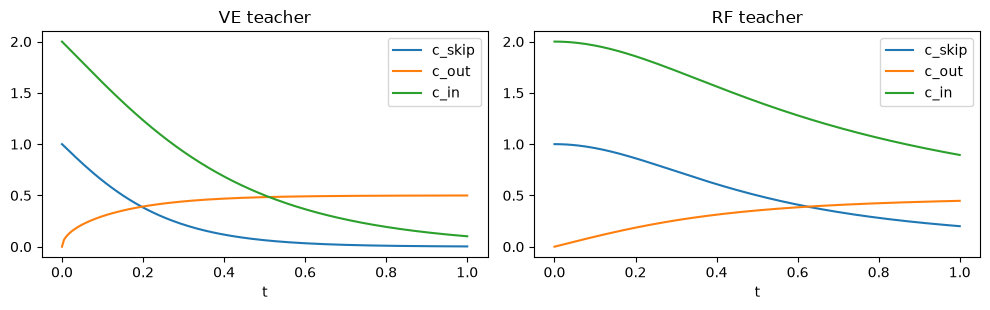

In [11]:
from consistency.distances import pseudo_huber_distance
from consistency.distillation import consistency_distillation_loss
from consistency.schedules import ConstantSchedule
from evaluation.compare import RF_TAU_MAX, SIGMA_DATA
from models.consistency_wrapper import ConsistencyWrapper
from sampling.consistency_sampler import ConsistencySampler

# evaluation.compare switches matplotlib to a non-interactive backend.
%matplotlib inline


def make_cm(backbone, process):
    # The same wrapper as in training: VE uses a ScoreNet backbone, RF a VelocityNet.
    return ConsistencyWrapper(backbone=backbone, sigma_data=SIGMA_DATA, eps=EPS, sigma_t=process.sigma_t).to(device).eval()


cm_ve = load_state(make_cm(ScoreNet(marginal_prob_std=None), ve), "./checkpoints/mnist_all_cm_ve.pth", device)

x = torch.randn(4, 1, 28, 28, device=device)
with torch.no_grad():
    error = (cm_ve(x, torch.full((4,), EPS, device=device)) - x).abs().max().item()
print(f"Boundary condition: max |f(x, eps) - x| = {error:.1e}")

t_plot = torch.linspace(EPS, 1.0, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (name, process) in zip(axes, [("VE", ve), ("RF", rf)]):
    wrapper = ConsistencyWrapper(backbone=None, sigma_data=SIGMA_DATA, eps=EPS, sigma_t=process.sigma_t)
    for coefficient in ["c_skip", "c_out", "c_in"]:
        ax.plot(t_plot, getattr(wrapper, coefficient)(t_plot), label=coefficient)
    ax.set_title(f"{name} teacher")
    ax.set_xlabel("t")
    ax.legend()
plt.tight_layout()
plt.show()

Near $t = \varepsilon$ the model copies its input ($c_\text{skip} \approx 1$);
as the noise grows, the output comes more and more from the network
($c_\text{out}$ grows). For VE this happens very quickly, because $\sigma(t)$
explodes; for RF, where $\sigma(t) = t$, it is gradual. $c_\text{in}$ scales
the input so the network always sees values of roughly unit variance.

#### The distillation loss

`consistency_distillation_loss` (`system/consistency/distillation.py`)
implements Algorithm 2 of Song et al. (2023). For each image $x_0$ of a batch:

1. pick two adjacent times $t_n < t_{n+1}$ of a grid of $N = 150$ points;
2. noise the image to $x_{t_{n+1}}$ with the teacher's forward process;
3. take **one teacher ODE step** back to $\hat{x}_{t_n}$ (Heun for VE, Euler
   for RF). Both points now lie (approximately) on the same trajectory;
4. ask the model to give the same output at both points:

$$\mathcal{L} = d\Big(f_\theta(x_{t_{n+1}}, t_{n+1}),\ f_{\theta^-}(\hat{x}_{t_n}, t_n)\Big).$$

$f_{\theta^-}$ is the *target network*, an exponential moving average (EMA,
rate $\mu = 0.95$) of $f_\theta$ that receives no gradient. $d$ is the
pseudo-Huber distance of Song & Dhariwal (2024). Since $f(x, \varepsilon) = x$
is fixed, consistency propagates from the clean end of each trajectory to the
noisy end during training.

Let us follow one step of this loss with the trained CM-VE, for a fixed pair
of adjacent times of the grid and the digits of the setup batch.

t_n = 0.455 (sigma = 1.66),  t_n+1 = 0.467 (sigma = 1.73)
Distance between the two predictions: 0.1913


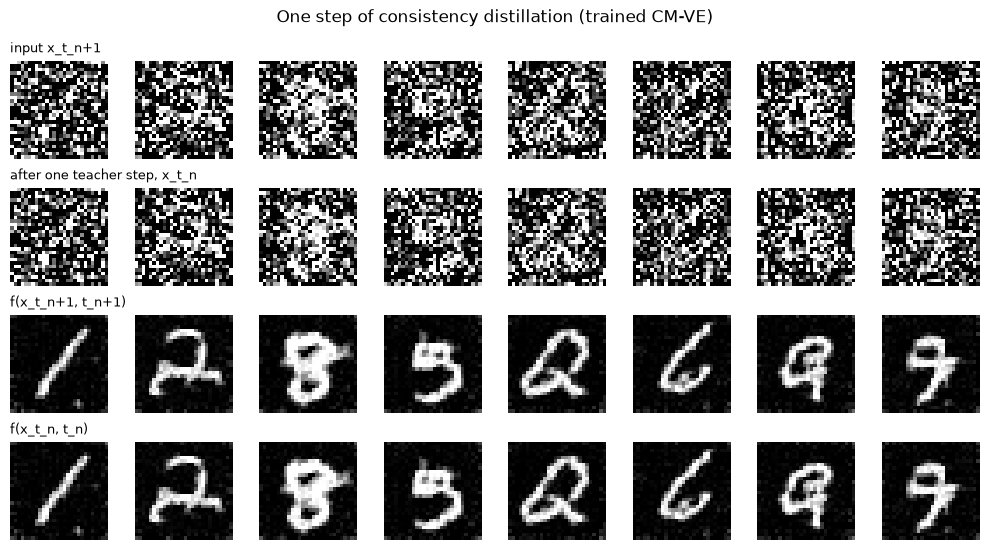

consistency_distillation_loss on the setup batch: 0.0669


In [12]:
x_batch = images[:N_SHOW].to(device)
t_grid = ve_teacher.time_grid(150).to(device)
n = 100  # a pair of adjacent grid points (t_n, t_n+1) at a medium noise level
t_n, t_next = t_grid[n].expand(N_SHOW), t_grid[n + 1].expand(N_SHOW)

torch.manual_seed(SEED)
x_next = ve_teacher.forward_sample(x_batch, t_next)  # step 2: noise the images
with torch.no_grad():
    x_n = ve_teacher.ode_step(x_next, t_next, t_n)  # step 3: one teacher step
    pred_next, pred_n = cm_ve(x_next, t_next), cm_ve(x_n, t_n)  # step 4: both predictions

print(f"t_n = {t_n[0]:.3f} (sigma = {ve.sigma_t(t_n[0]):.2f}),  t_n+1 = {t_next[0]:.3f} (sigma = {ve.sigma_t(t_next[0]):.2f})")
print(f"Distance between the two predictions: {pseudo_huber_distance(pred_next, pred_n).item():.4f}")
show_rows({
    "input x_t_n+1": x_next,
    "after one teacher step, x_t_n": x_n,
    "f(x_t_n+1, t_n+1)": pred_next,
    "f(x_t_n, t_n)": pred_n,
}, "One step of consistency distillation (trained CM-VE)")

# The same computation as the training script, with a random pair (t_n, t_n+1) per image.
with torch.no_grad():
    loss = consistency_distillation_loss(cm_ve, cm_ve, ve_teacher, images.to(device), ConstantSchedule(150),
                                         iteration=0, distance_fn=pseudo_huber_distance)
print(f"consistency_distillation_loss on the setup batch: {loss.item():.4f}")

The two inputs are noisy and almost identical, and the trained model maps
both of them to (almost) the same clean digit: that is the self-consistency
the loss asks for. Training repeats this step for 40,000 mini-batches:
`system/training/consistency_distillation_training.py` minimizes the loss with
Adam (learning rate $4 \cdot 10^{-4}$, batch size 64), updates the target
network after each step, and keeps a second, slower EMA of the weights
(rate 0.9999) that is the one saved and used for sampling. It takes more than
an hour per model, so we load the trained checkpoints. They were
produced with:

```bash
python system/training/consistency_distillation_training.py --teacher ve
python system/training/consistency_distillation_training.py --teacher rf
python system/training/consistency_distillation_training.py --teacher rf \
    --teacher-checkpoint ./checkpoints/mnist_all_2rf_ema.pth --tag reflow
```

### 3.2 One-step and multistep sampling

#### One step

Once trained, generating is a single network evaluation: draw noise
$x_T \sim \mathcal{N}(0, \sigma(T)^2 I)$ and return $f_\theta(x_T, T)$.

#### Multistep sampling

Algorithm 1 of the paper trades a few extra evaluations for quality. After
the first prediction $x \leftarrow f_\theta(x_T, T)$, for each intermediate time
$\tau_1 > \tau_2 > \dots$:

1. **re-noise** the prediction to time $\tau$ with the teacher's forward process,
   - VE: $x_\tau = x + \sqrt{\sigma(\tau)^2 - \sigma(\varepsilon)^2}\; z$,
   - RF: $x_\tau = (1 - \tau)\, x + \tau\, x_1$;
2. **denoise** it again in one jump, $x \leftarrow f_\theta(x_\tau, \tau)$.

Every prediction is clamped to the data range $[-1, 1]$ before being re-noised.

Each step costs one network evaluation, so $n$ steps cost $\text{NFE} = n$.
`ConsistencySampler` (`system/sampling/consistency_sampler.py`) implements both
cases. For VE the times $\tau$ come from a Karras grid; for RF they are spaced
uniformly from $\tau_\text{max} = 0.5$ down to $\varepsilon$, the value we
chose by inspecting the samples (see below). This is the same choice as in
the evaluation of section 4.

In [13]:
cm_rf = load_state(make_cm(VelocityNet(), rf), "./checkpoints/mnist_all_cm_rf.pth", device)
cm_rf_reflow = load_state(make_cm(VelocityNet(), rf), "./checkpoints/mnist_all_cm_rf_reflow.pth", device)


def cm_generate(cm, process, x_T, n_steps, tau_max=RF_TAU_MAX):
    # n_steps evaluations of the consistency model, starting from the noise x_T.
    sampler = ConsistencySampler(process, eps=EPS)
    if n_steps == 1:
        taus = None
    elif process.kind == "RF":
        taus = torch.linspace(tau_max, EPS, n_steps)[:-1].tolist()
    else:
        taus = sampler.karras_intermediate_times(n_steps)
    return sampler.sample(tuple(x_T.shape), cm, device=device, intermediate_times=taus, x_T=x_T)


print("VE re-noising times for 4 steps:", [round(t, 3) for t in ConsistencySampler(ve, eps=EPS).karras_intermediate_times(4)])
print("RF re-noising times for 4 steps:", [round(t, 3) for t in torch.linspace(RF_TAU_MAX, EPS, 4)[:-1].tolist()])

VE re-noising times for 4 steps: [0.596, 0.16, 0.004]
RF re-noising times for 4 steps: [0.5, 0.333, 0.167]


We now generate with 1, 2 and 4 steps from the **same initial noise** as the
teachers of section 2, and put the teachers with 50 steps on top as a
reference. VE first:

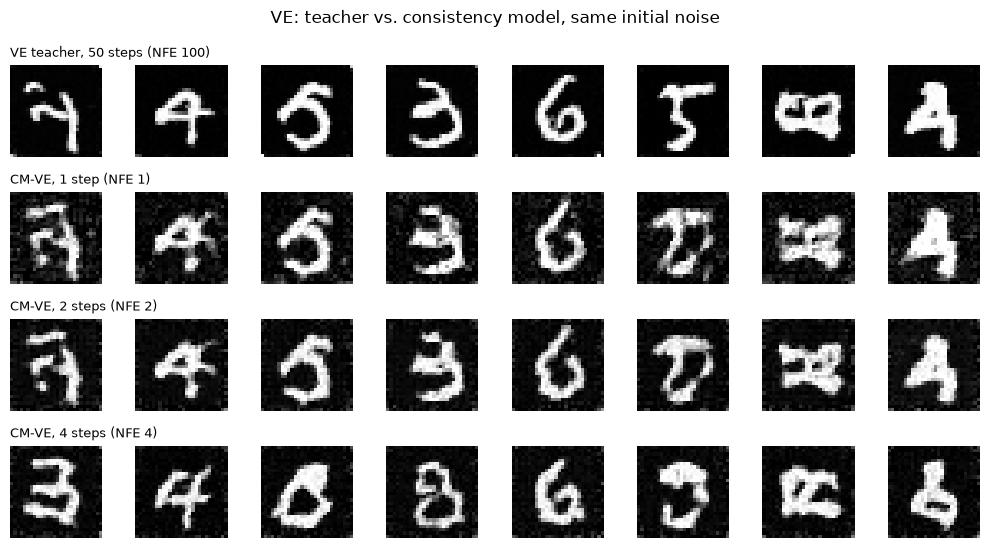

In [14]:
rows = {"VE teacher, 50 steps (NFE 100)": ve_generate(x_T_ve, 50)}
for n in [1, 2, 4]:
    rows[f"CM-VE, {n} step{'s' if n > 1 else ''} (NFE {n})"] = cm_generate(cm_ve, ve, x_T_ve, n)
show_rows(rows, "VE: teacher vs. consistency model, same initial noise")

And Rectified Flow, with the consistency models distilled from the 1-RF and
from the reflowed 2-RF:

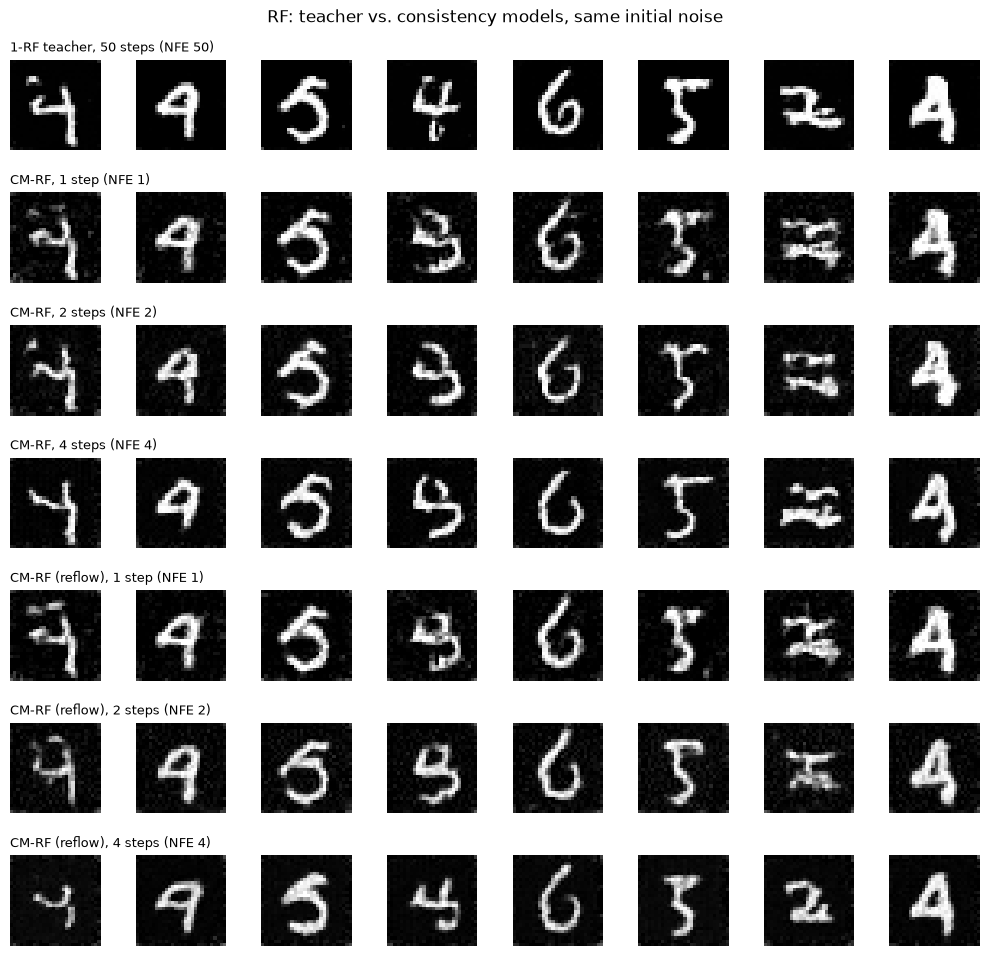

In [15]:
_, x_rf_teacher = RectifiedFlowSampler(rf, n_steps=50).sample(
    tuple(x_T_rf.shape), rf_teachers["1-RF"], device=device, x_T=x_T_rf)
rows = {"1-RF teacher, 50 steps (NFE 50)": x_rf_teacher * 2 - 1}
for name, cm in [("CM-RF", cm_rf), ("CM-RF (reflow)", cm_rf_reflow)]:
    for n in [1, 2, 4]:
        rows[f"{name}, {n} step{'s' if n > 1 else ''} (NFE {n})"] = cm_generate(cm, rf, x_T_rf, n)
show_rows(rows, "RF: teacher vs. consistency models, same initial noise")

With a single evaluation the consistency models already produce
recognizable digits, often the same digit the teacher reaches from that
noise: they have learned to jump to the end of the teacher's trajectory. The
1-step samples are noisier than the teacher's, and one or three extra steps
clean them up. Section 4 quantifies this.

#### The re-noising time $\tau$

How much noise is added back in multistep sampling matters. A small
$\tau_\text{max}$ barely changes the first prediction, while a large one
almost erases it, and the model has to regenerate the digit from heavy
noise. Below, CM-RF with 4 steps for several values of $\tau_\text{max}$.

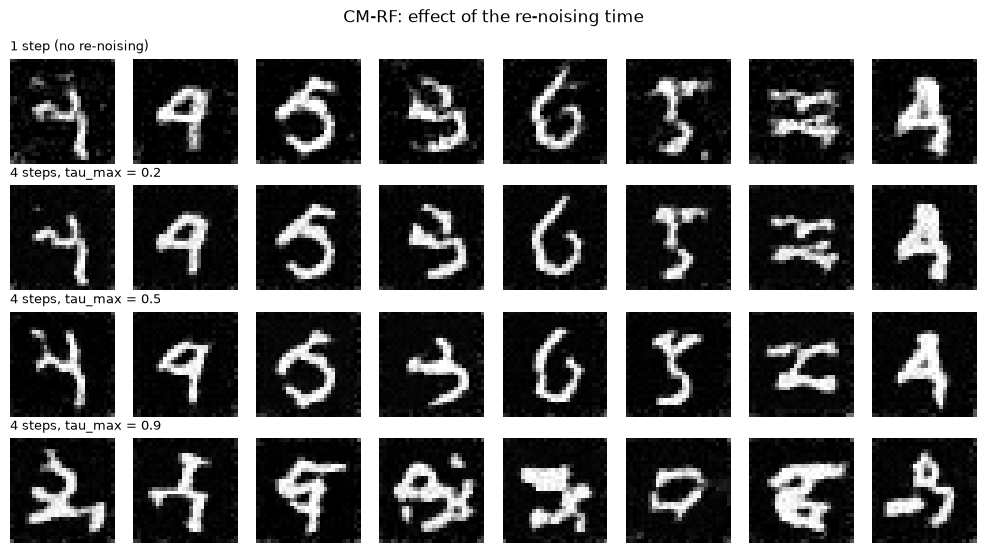

In [16]:
rows = {"1 step (no re-noising)": cm_generate(cm_rf, rf, x_T_rf, 1)}
for tau_max in [0.2, 0.5, 0.9]:
    rows[f"4 steps, tau_max = {tau_max}"] = cm_generate(cm_rf, rf, x_T_rf, 4, tau_max=tau_max)
show_rows(rows, "CM-RF: effect of the re-noising time")

With $\tau_\text{max} = 0.2$ the samples are almost the 1-step ones; with
$0.9$ many digits change or break; $0.5$ cleans the digits while keeping
them. `system/tests/cm_tau_sweep.py` runs a finer sweep, which is how we
chose $\tau_\text{max} = 0.5$.


### 3.3 Consistency training

Distillation needs a trained teacher. **Consistency training** (CT, Algorithm 3
of the paper) removes it: the two points of each pair are built from the same
image $x_0$ and the **same noise** $z$,

$$x_{t_{n+1}} = x_0 + \sigma(t_{n+1})\, z, \qquad x_{t_n} = x_0 + \sigma(t_n)\, z,$$

which lie, in expectation, on the same trajectory of the VE process, so the
teacher's ODE step is no longer needed. The loss is the same as in CD,
$d\big(f_\theta(x_{t_{n+1}}, t_{n+1}),\ f_{\theta^-}(x_{t_n}, t_n)\big)$, with the
pseudo-Huber distance (`system/consistency/ct_loss.py`). We only implemented it
for the VE process.

Without a teacher, the number of grid points $N(k)$ and the EMA rate $\mu(k)$ of
the target network follow a curriculum over the training iterations $k$: training
starts on a coarse grid (easy, low-variance targets) and refines it up to
$N = 151$ (`DiscretizationSchedule` and `EMADecaySchedule` in
`system/consistency/schedules.py`).

**Improved consistency training** (iCT, Song & Dhariwal, 2024,
`system/consistency/ict_loss.py`) changes four things: there is no EMA target (the
target is the same network without gradients), $N$ doubles in equal stages (from
11 to 161), the noise levels are drawn from a lognormal distribution that favours
intermediate values, and the loss is weighted by $1 / (\sigma_{n+1} - \sigma_n)$.

We trained four models without a teacher (recipes in the appendix of the report):

| Model | Script | Checkpoint |
|---|---|---|
| CT v1 | `consistency_training.py` (20,000 iterations) | `mnist_all_cm_ve_ct.pth` |
| CT v2 | `consistency_training_v2.py` (40,000 iterations, the budget of CD) | `mnist_all_cm_ve_ct_v2.pth` |
| iCT v1 | `consistency_training_improved.py`, two phases (about 5.4 M images) | `mnist_all_cm_ve_ict_n640.pth` |
| iCT v2 | `consistency_training_improved.py --iterations 40000 --sample-ema 0.9995 --constant-lr` | `mnist_all_cm_ve_ict_40k_ema_lrconst.pth` |

First, the two curricula over a run of 40,000 iterations:


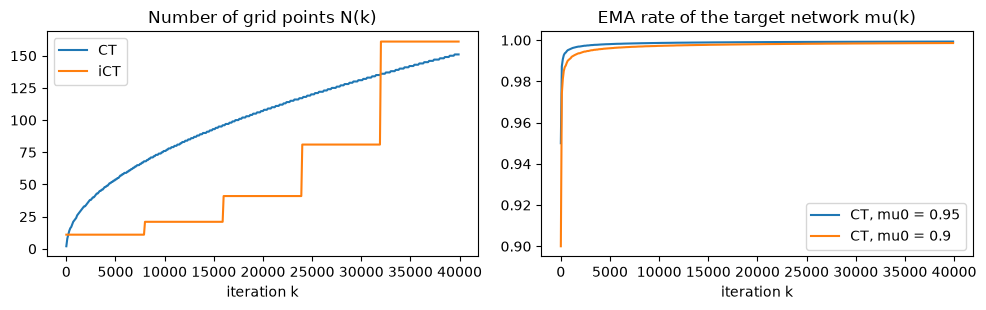

In [17]:
from consistency.ct_loss import consistency_training_loss
from consistency.ict_loss import ImprovedDiscretizationSchedule, improved_consistency_training_loss
from consistency.schedules import DiscretizationSchedule, EMADecaySchedule

K = 40_000
k = np.arange(0, K, 100)
ct_schedule = DiscretizationSchedule(K=K)
ict_schedule = ImprovedDiscretizationSchedule(K=K, s0=10, s1=160)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(k, [ct_schedule(i) for i in k], label="CT")
axes[0].plot(k, [ict_schedule(i) for i in k], label="iCT")
axes[0].set_title("Number of grid points N(k)")
for mu0 in [0.95, 0.9]:
    axes[1].plot(k, [EMADecaySchedule(ct_schedule, mu0=mu0)(i) for i in k], label=f"CT, mu0 = {mu0}")
axes[1].set_title("EMA rate of the target network mu(k)")
for ax in axes:
    ax.set_xlabel("iteration k")
    ax.legend()
plt.tight_layout()
plt.show()

CT grows $N$ smoothly and couples $\mu$ to it, so the target network follows the
online one more slowly as the grid gets finer. iCT has no target network to
schedule and doubles $N$ at the start of each of its five stages.

Let us build one CT pair on the setup batch and look at it with the trained CT v2
model. Both inputs share the same noise, so they differ only in how much of it
they contain:

Distance between the two predictions: 0.4283


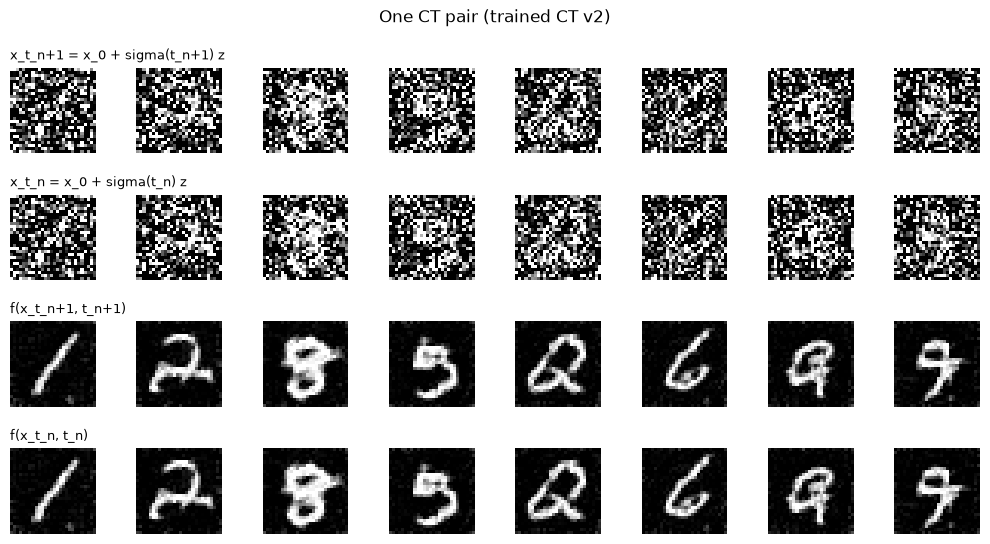

CT loss (CT v2): 0.2167   |   iCT loss (iCT v2, weighted): 5.9289


In [18]:
ct_models = {
    "CT v1": "./checkpoints/mnist_all_cm_ve_ct.pth",
    "CT v2": "./checkpoints/mnist_all_cm_ve_ct_v2.pth",
    "iCT v1": "./checkpoints/mnist_all_cm_ve_ict_n640.pth",
    "iCT v2": "./checkpoints/mnist_all_cm_ve_ict_40k_ema_lrconst.pth",
}
ct_models = {name: load_state(make_cm(ScoreNet(marginal_prob_std=None), ve), path, device)
             for name, path in ct_models.items()}

n = 100  # the same pair of adjacent grid points as in the distillation example
t_n, t_next = t_grid[n].expand(N_SHOW), t_grid[n + 1].expand(N_SHOW)
torch.manual_seed(SEED)
z = torch.randn_like(x_batch)
x_next = x_batch + ve.sigma_t(t_next).view(-1, 1, 1, 1) * z  # same noise z ...
x_n = x_batch + ve.sigma_t(t_n).view(-1, 1, 1, 1) * z  # ... at two noise levels
with torch.no_grad():
    pred_next, pred_n = ct_models["CT v2"](x_next, t_next), ct_models["CT v2"](x_n, t_n)
print(f"Distance between the two predictions: {pseudo_huber_distance(pred_next, pred_n).item():.4f}")
show_rows({
    "x_t_n+1 = x_0 + sigma(t_n+1) z": x_next,
    "x_t_n = x_0 + sigma(t_n) z": x_n,
    "f(x_t_n+1, t_n+1)": pred_next,
    "f(x_t_n, t_n)": pred_n,
}, "One CT pair (trained CT v2)")

# The same losses as the training scripts, at the end of their curricula (k = K).
with torch.no_grad():
    batch = images.to(device)
    ct = consistency_training_loss(ct_models["CT v2"], ct_models["CT v2"], ve, batch, ct_schedule, K,
                                   pseudo_huber_distance, EPS)
    ict = improved_consistency_training_loss(ct_models["iCT v2"], ve, batch, ict_schedule, K, EPS)
print(f"CT loss (CT v2): {ct.item():.4f}   |   iCT loss (iCT v2, weighted): {ict.item():.4f}")

The iCT loss is larger only because of its $1 / (\sigma_{n+1} - \sigma_n)$
weighting; the two values are not comparable.

Finally, the four models with one and four steps, from the same initial noise as
the VE teacher and CM-VE (CD) above:

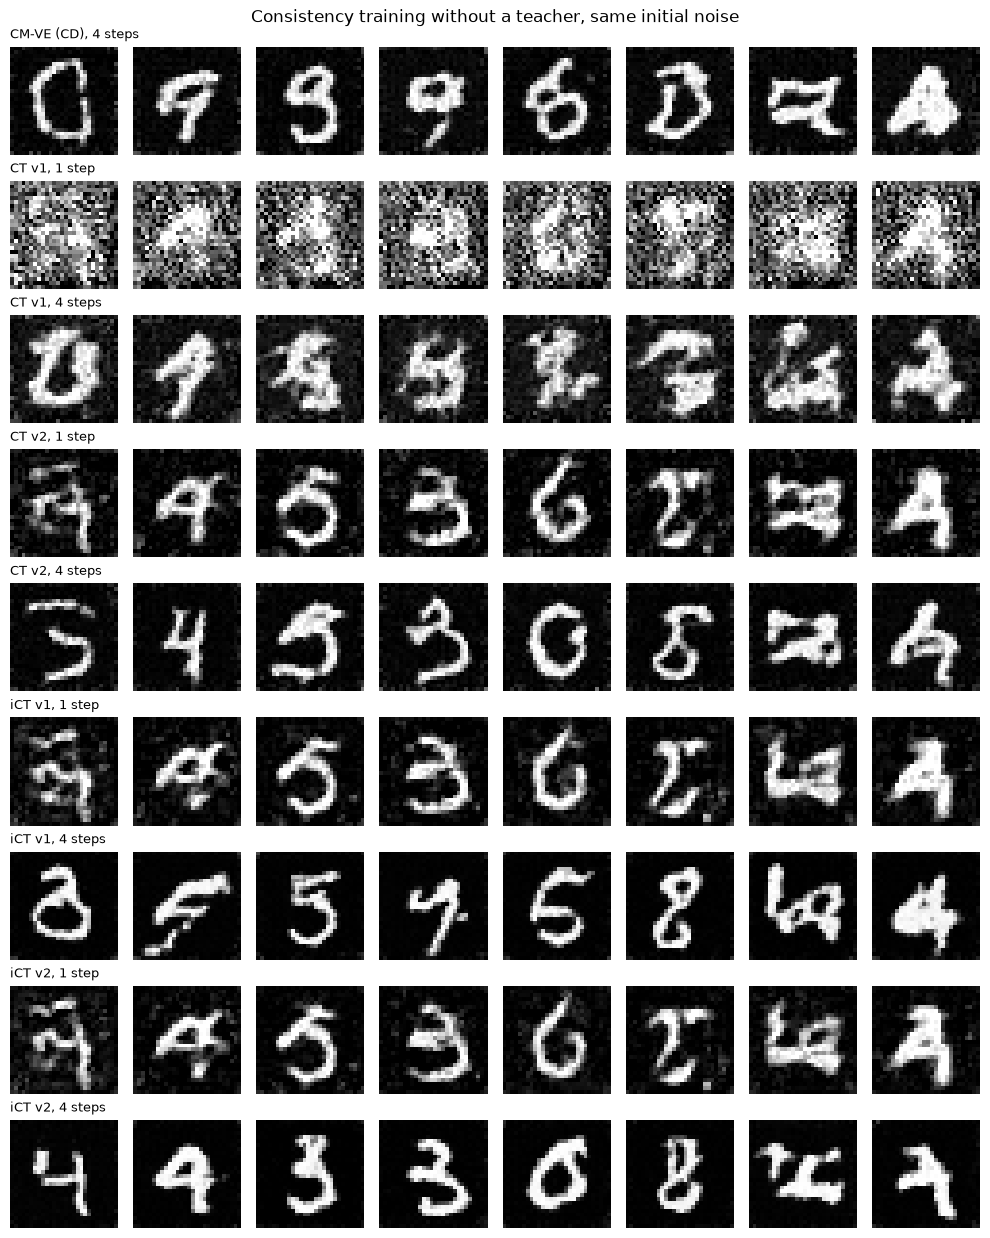

In [19]:
rows = {"CM-VE (CD), 4 steps": cm_generate(cm_ve, ve, x_T_ve, 4)}
for name, cm in ct_models.items():
    for n_steps in [1, 4]:
        rows[f"{name}, {n_steps} step{'s' if n_steps > 1 else ''}"] = cm_generate(cm, ve, x_T_ve, n_steps)
show_rows(rows, "Consistency training without a teacher, same initial noise")

CT v1, trained for 20,000 iterations, only makes noisy blobs, even with four
steps. CT v2, with the same number of training images as CD, makes digits
comparable to CM-VE (CD), and the iCT models give the cleanest four-step samples
of the VE family, although some digits are still deformed. Section 4 and the
report quantify these differences: with four steps, iCT v2 reaches an FD-MNIST of
160 against 323 for CM-VE (CD).

## 4. Evaluation

We compare teachers and consistency models with a small classifier trained on
MNIST: FD-MNIST and the fraction of recognizable samples measure quality, and
the entropy of the predicted digits measures diversity. The seed is reset so
that the results do not depend on the previous sections. Small differences
with `results/` are expected, because the reference images and the noise of
multistep sampling are random.

In [20]:
from evaluation import compare
from evaluation.classifier import MNISTClassifier
from evaluation.metrics import (
    confident_fraction, extract_features, fd_mnist,
    label_distribution, label_entropy, max_label_entropy, predict_proba,
)
from evaluation.timing import benchmark_generation_time

%matplotlib inline
set_seed(SEED)

[INFO] Seed set to 42


### 4.1 The reference classifier

A small CNN trained with `system/training/classifier_training.py`. We load its
weights and check its accuracy on the test set.

In [21]:
classifier = compare.load_state(MNISTClassifier(), compare.CLASSIFIER_PATH, device)
print(classifier)
print(f"Parameters: {sum(p.numel() for p in classifier.parameters()):,}")

correct, total = 0, 0
with torch.no_grad():
    for x, y in get_dataloader(batch_size=1000, train=False, data_dir="./data"):
        correct += (classifier(x.to(device)).argmax(dim=1).cpu() == y).sum().item()
        total += y.numel()
print(f"Test accuracy: {100 * correct / total:.2f}%")

MNISTClassifier(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parameters: 421,642


Test accuracy: 99.00%


### 4.2 Why counting recognized digits is not enough

The classifier always picks a digit, even for images that are not digits.
Pure noise shows how often it does so with high confidence.

Real MNIST  recognized with confidence >= 0.9: 97.6%


Pure noise  recognized with confidence >= 0.9: 60.2%


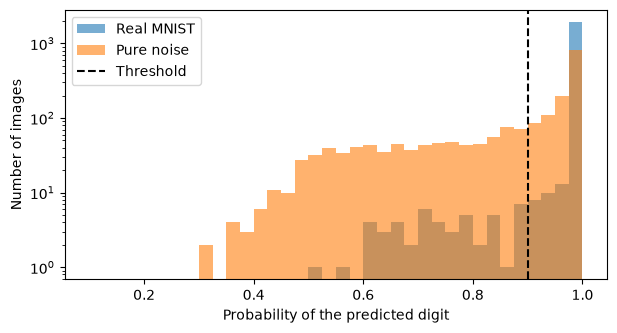

In [22]:
N_EVAL = compare.N_EVAL
real = compare.load_real_images(train=False, n=N_EVAL)
noise = torch.randn(N_EVAL, 1, 28, 28).clamp(-1.0, 1.0)

for name, images in [("Real MNIST", real), ("Pure noise", noise)]:
    fraction = confident_fraction(classifier, images, compare.CONFIDENCE_THRESHOLD)
    print(f"{name:11s} recognized with confidence >= {compare.CONFIDENCE_THRESHOLD}: {100 * fraction:.1f}%")

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0.1, 1.0, 37)
for name, images in [("Real MNIST", real), ("Pure noise", noise)]:
    confidence = predict_proba(classifier, images).max(dim=1).values.cpu().numpy()
    ax.hist(confidence, bins=bins, alpha=0.6, label=name)
ax.axvline(compare.CONFIDENCE_THRESHOLD, color="black", linestyle="--", label="Threshold")
ax.set_yscale("log")
ax.set_xlabel("Probability of the predicted digit")
ax.set_ylabel("Number of images")
ax.legend()
plt.show()

### 4.3 FD-MNIST

The Fréchet distance between the classifier features of generated and real
images (like FID, with our classifier instead of Inception). Real test images
and pure noise give two reference values.

In [23]:
reference = extract_features(classifier, compare.load_real_images(train=True, n=compare.N_REFERENCE))
print("Reference features:", reference.shape)

for name, images in [("Real MNIST", real), ("Pure noise", noise)]:
    print(f"{name:11s} FD-MNIST = {fd_mnist(classifier, images, reference):.1f}")

Reference features: (10000, 128)


Real MNIST  FD-MNIST = 47.0


Pure noise  FD-MNIST = 2929.6



### 4.4 Evaluating the generators

The two VE teachers with 10 steps against CM-VE with 1, 2 and 4 steps, all
starting from the same noise. CM-VE was distilled from the **raw** teacher (40
epochs, no EMA), not from the better EMA one that we used in section 2, so we
show both.


In [24]:
models = {m.name: m for m in compare.MODELS}
selected = [
    models["VE teacher (EMA)"]._replace(steps=[10]),
    models["VE teacher (raw)"]._replace(steps=[10]),
    models["CM-VE (CD)"],
]
configs = [c for spec in selected for c in compare.build_configs(spec, device)]
x_T = configs[0].noise(N_EVAL, torch.Generator().manual_seed(42)).to(device)

samples = {}
for c in configs:
    samples[c.label] = compare.batched(c.generate, x_T)
    metrics, _ = compare.evaluate_samples(samples[c.label], classifier, reference)
    print(f"{c.label:30s} NFE={c.nfe:3d}  FD-MNIST={metrics['fd_mnist']:6.1f}  "
          f"recognizable={100 * metrics['recognizable']:5.1f}%  entropy={metrics['entropy']:.3f}")

VE teacher (EMA) · 10 steps    NFE= 20  FD-MNIST= 118.1  recognizable= 79.9%  entropy=2.253


VE teacher (raw) · 10 steps    NFE= 20  FD-MNIST= 206.2  recognizable= 79.0%  entropy=2.188


CM-VE (CD) · 1 step            NFE=  1  FD-MNIST= 450.0  recognizable= 64.2%  entropy=2.186


CM-VE (CD) · 2 steps           NFE=  2  FD-MNIST= 384.7  recognizable= 66.6%  entropy=2.202


CM-VE (CD) · 4 steps           NFE=  4  FD-MNIST= 303.9  recognizable= 72.0%  entropy=2.222


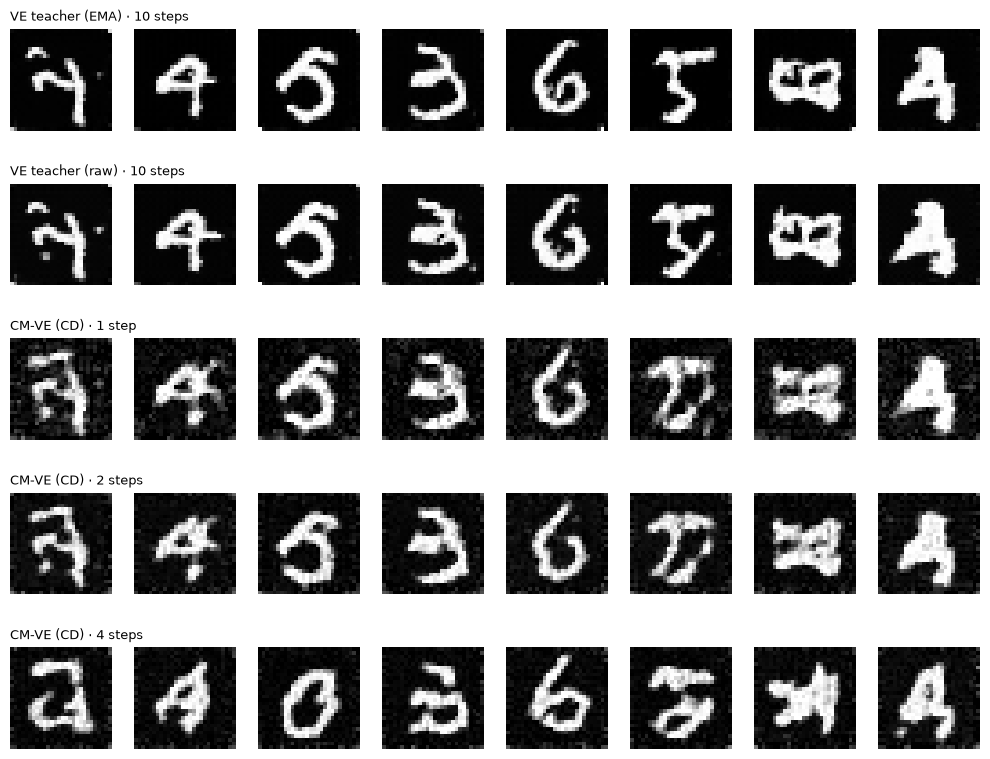

In [25]:
fig, axes = plt.subplots(len(samples), 8, figsize=(10, 1.6 * len(samples)))
for row, (label, images) in zip(axes, samples.items()):
    for ax, image in zip(row, images[:8]):
        ax.imshow((image[0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    row[0].set_title(label, fontsize=9, loc="left")
plt.tight_layout()
plt.show()

### 4.5 Diversity

How often each digit is generated, and the entropy of that distribution
(maximum $\ln 10 \approx 2.30$).

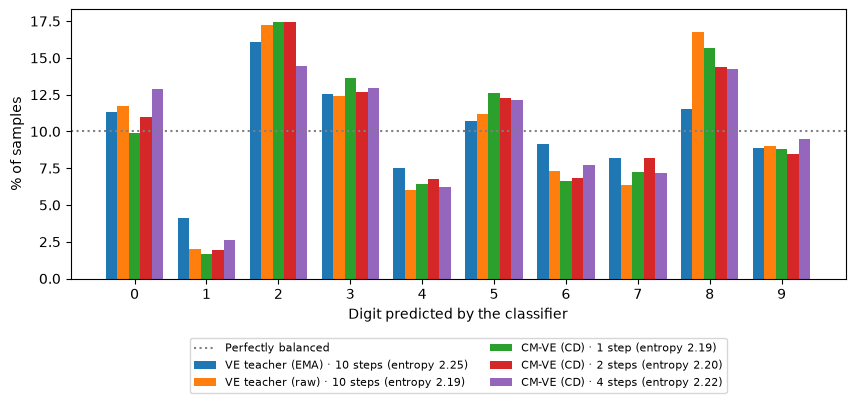

Maximum entropy: ln 10 = 2.303


In [26]:
digits = np.arange(10)
width = 0.8 / len(samples)
fig, ax = plt.subplots(figsize=(10, 3.5))
for i, (label, images) in enumerate(samples.items()):
    distribution = label_distribution(classifier, images).cpu()
    ax.bar(digits + i * width, 100 * distribution.numpy(), width,
           label=f"{label} (entropy {label_entropy(distribution):.2f})")
ax.axhline(10, color="gray", linestyle=":", label="Perfectly balanced")
ax.set_xticks(digits + 0.4 - width / 2, digits)
ax.set_xlabel("Digit predicted by the classifier")
ax.set_ylabel("% of samples")
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.show()
print(f"Maximum entropy: ln 10 = {max_label_entropy():.3f}")

### 4.6 Sampling speed

Generation time as a function of the number of images $N$.

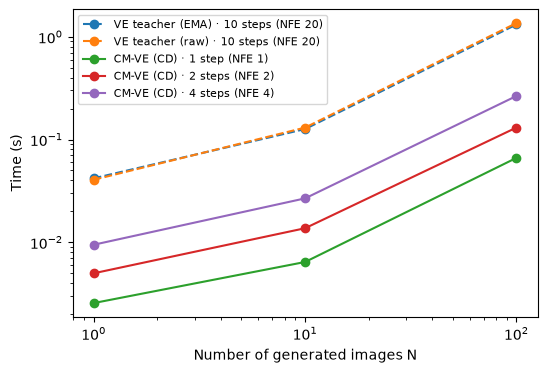

VE teacher (EMA) · 10 steps     13.17 ms/image   speed-up vs. the 10-step teacher: x1.0
VE teacher (raw) · 10 steps     13.60 ms/image   speed-up vs. the 10-step teacher: x1.0
CM-VE (CD) · 1 step              0.66 ms/image   speed-up vs. the 10-step teacher: x19.9
CM-VE (CD) · 2 steps             1.31 ms/image   speed-up vs. the 10-step teacher: x10.1
CM-VE (CD) · 4 steps             2.65 ms/image   speed-up vs. the 10-step teacher: x5.0


In [27]:
sizes = [1, 10, 100]
timings = {
    c.label: benchmark_generation_time(lambda n, c=c: c.generate(c.noise(n).to(device)), sizes, n_repeats=3)
    for c in configs
}

fig, ax = plt.subplots(figsize=(6, 4))
for c in configs:
    ax.plot(sizes, [timings[c.label][n] for n in sizes], "--" if c.is_teacher else "-",
            marker="o", label=f"{c.label} (NFE {c.nfe})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of generated images N")
ax.set_ylabel("Time (s)")
ax.legend(fontsize=8)
plt.show()

n = max(sizes)
teacher = configs[0].label
for c in configs:
    t = timings[c.label][n]
    print(f"{c.label:30s} {1000 * t / n:6.2f} ms/image   speed-up vs. the 10-step teacher: x{timings[teacher][n] / t:.1f}")

### Putting it all together

`system/evaluation/compare.py` runs this evaluation for every model of the
project and writes the table and figures to `results/`. Run it from the root of the repository:

```bash
python system/evaluation/compare.py
```


## 5. Summary

- A **consistency model** wraps a U-Net so that $f_\theta(x, \varepsilon) = x$
  holds by construction, and learns to map every point of a trajectory to its
  clean end.
- **Consistency distillation** learns it from a teacher: one teacher ODE step
  gives two points of the same trajectory, and the model must give the same output
  at both. We distilled a VE diffusion teacher and a Rectified Flow teacher.
- **Consistency training** needs no teacher: both points share the same noise. A
  short run with the original recipe (CT v1) fails, but with the training images
  of CD (CT v2) it matches distillation, and the improved recipe (iCT) is better
  still.
- With **one evaluation**, the consistency models make recognizable digits about
  50 to 95 times faster than the 50-step teachers; a few extra steps improve
  them, but they do not reach the quality of their teachers, and a teacher with
  10 steps is already better.
- **FD-MNIST** on the features of our classifier is the main quality metric,
  because the classifier labels many noise images as digits with high confidence.

The complete comparison of all the models, with every number of steps, is in
`results/` and in the report.
